
Image 1  (247x222)
Result                PSNR (dB)    SSIM   Sharpness
Original                    inf   1.000      7614.8
Ideal D0=30               19.70   0.416        75.3
Butterworth D0=30         20.29   0.489        83.0
Gaussian D0=30            20.72   0.541       128.9
Ideal D0=60               21.61   0.657       699.3
Butterworth D0=60         23.14   0.756       594.7
Gaussian D0=60            24.59   0.829       967.9
High-boost k=1            21.44   0.623       270.1
High-boost k=2            21.94   0.680       471.1
Edge pixels: original = 18.60%, after smoothing + sharpening + cleanup = 17.96%


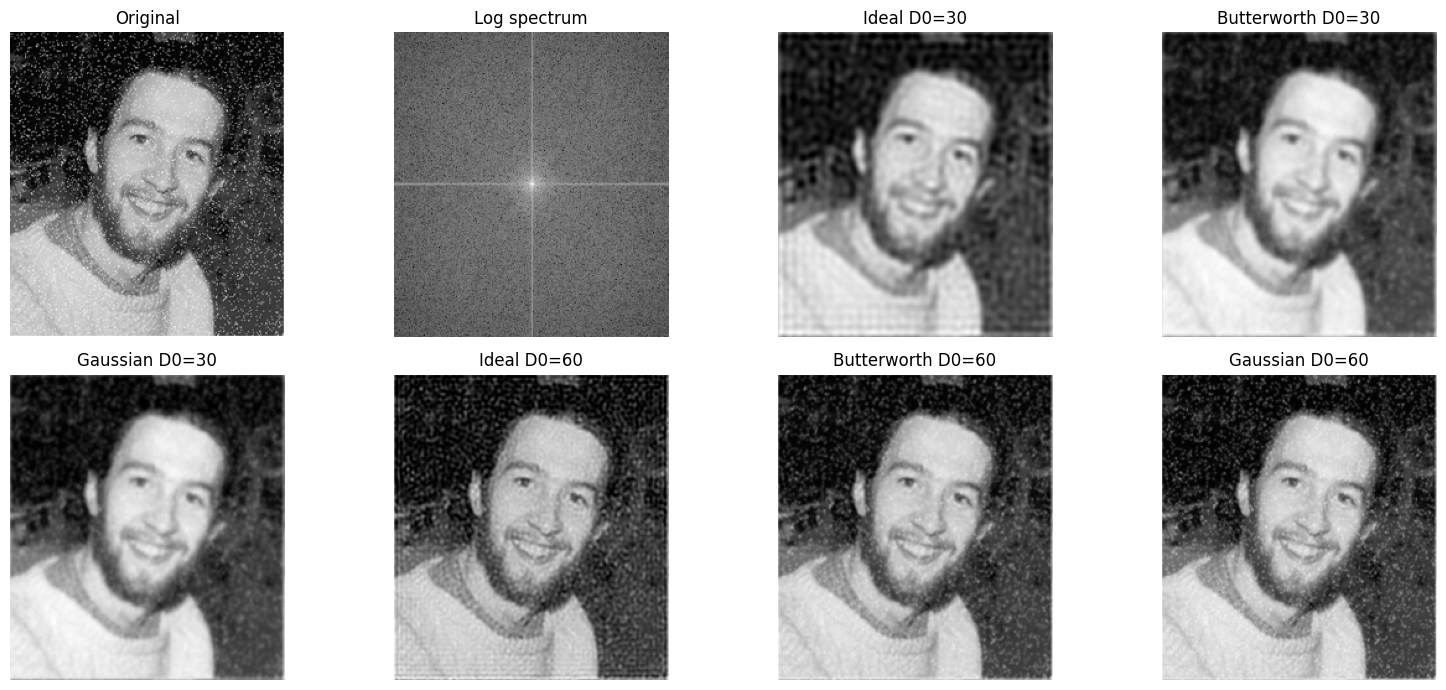

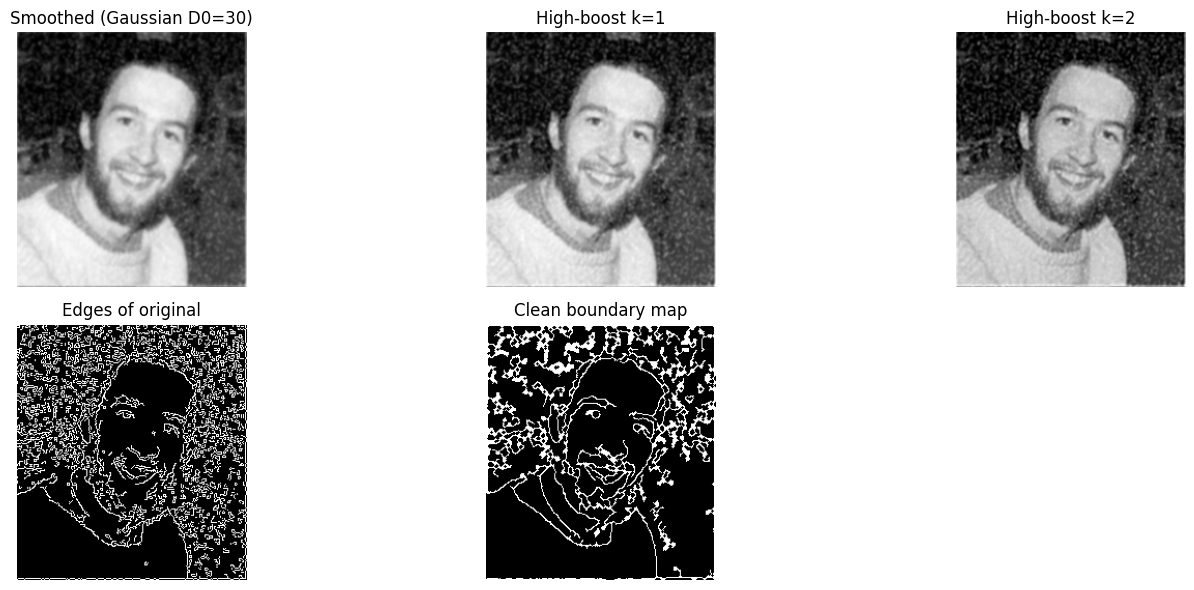

 

Image 2  (253x173)
Result                PSNR (dB)    SSIM   Sharpness
Original                    inf   1.000     22201.2
Ideal D0=30               13.94   0.361       221.9
Butterworth D0=30         14.88   0.472       258.7
Gaussian D0=30            15.70   0.575       587.1
Ideal D0=60               17.69   0.797      5158.2
Butterworth D0=60         19.65   0.860      3829.0
Gaussian D0=60            21.33   0.907      5566.1
High-boost k=1            17.05   0.718      1508.9
High-boost k=2            18.13   0.805      2886.0
Edge pixels: original = 25.23%, after smoothing + sharpening + cleanup = 34.53%


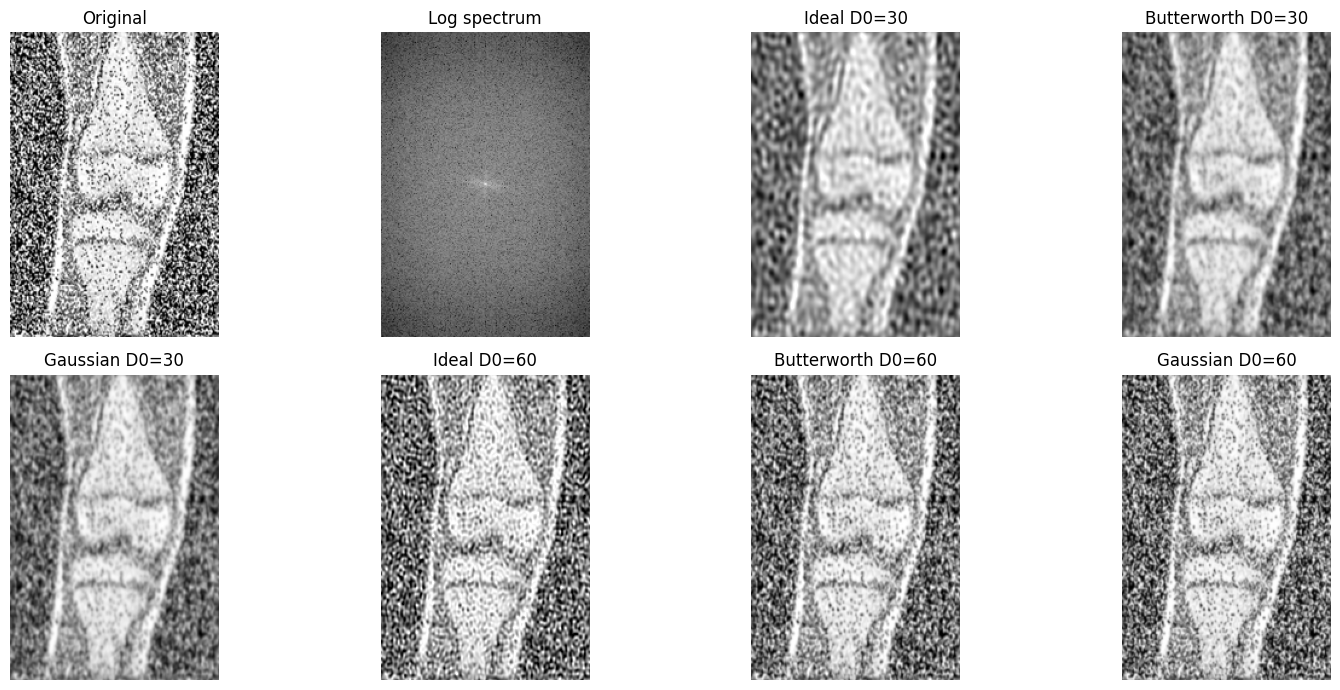

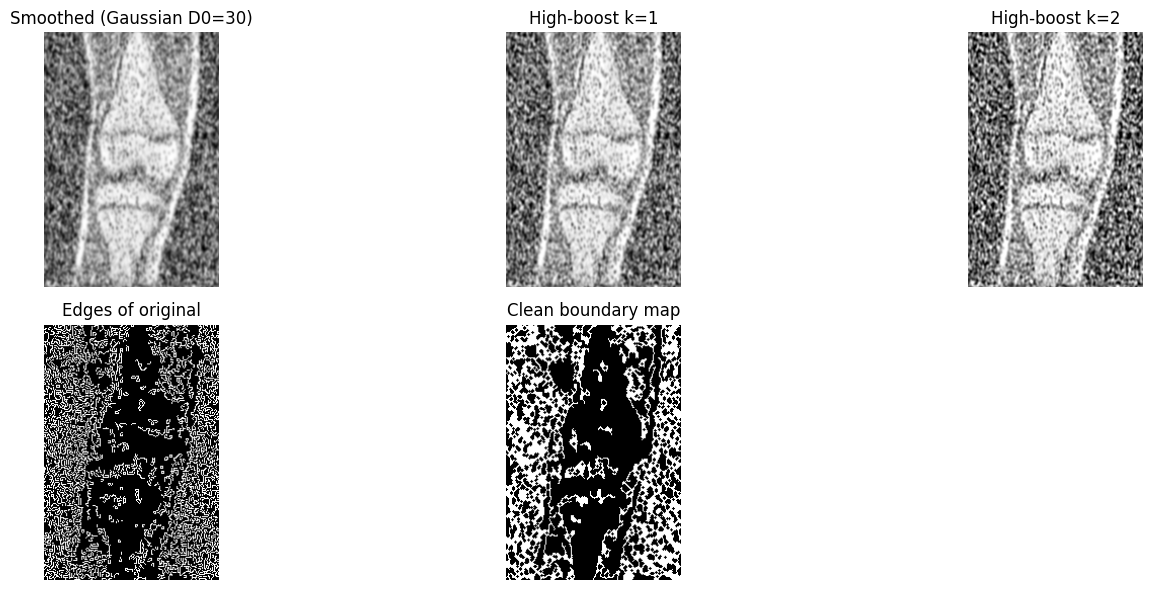

 

Image 3  (301x602)
Result                PSNR (dB)    SSIM   Sharpness
Original                    inf   1.000      6292.2
Ideal D0=30               17.87   0.324        16.8
Butterworth D0=30         18.35   0.354        16.0
Gaussian D0=30            18.70   0.389        24.6
Ideal D0=60               19.46   0.488       131.5
Butterworth D0=60         20.29   0.555       115.7
Gaussian D0=60            20.95   0.610       196.0
High-boost k=1            19.28   0.454        56.7
High-boost k=2            19.59   0.501       101.6
Edge pixels: original = 13.83%, after smoothing + sharpening + cleanup = 9.12%


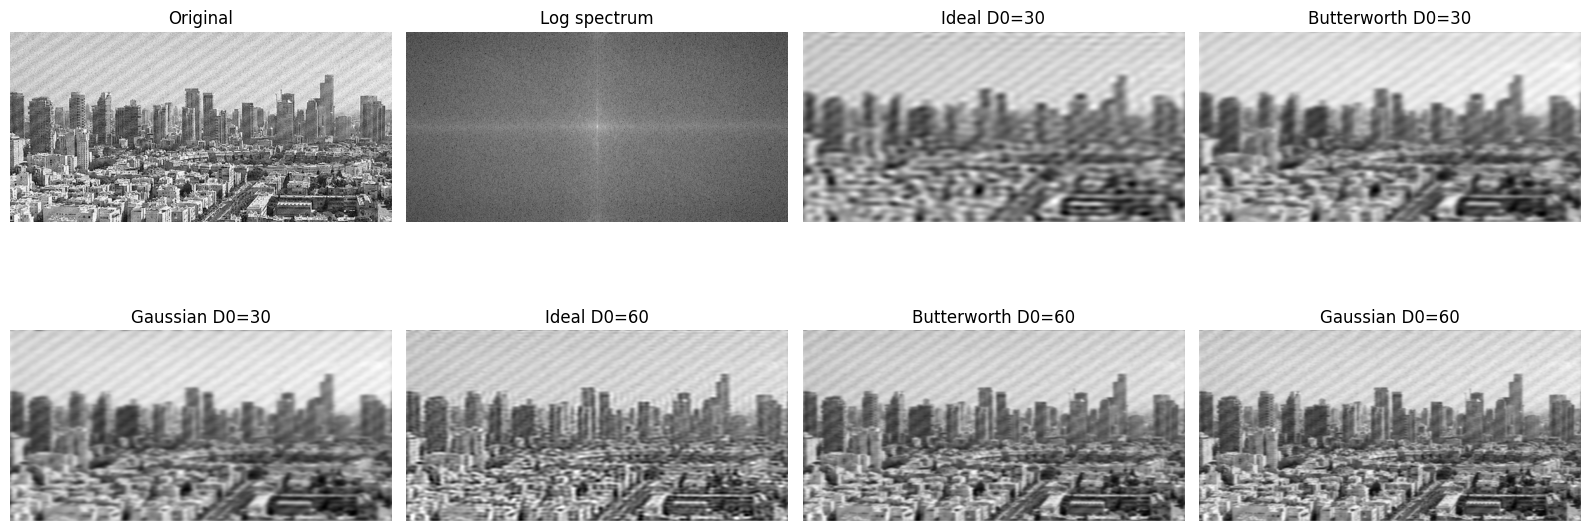

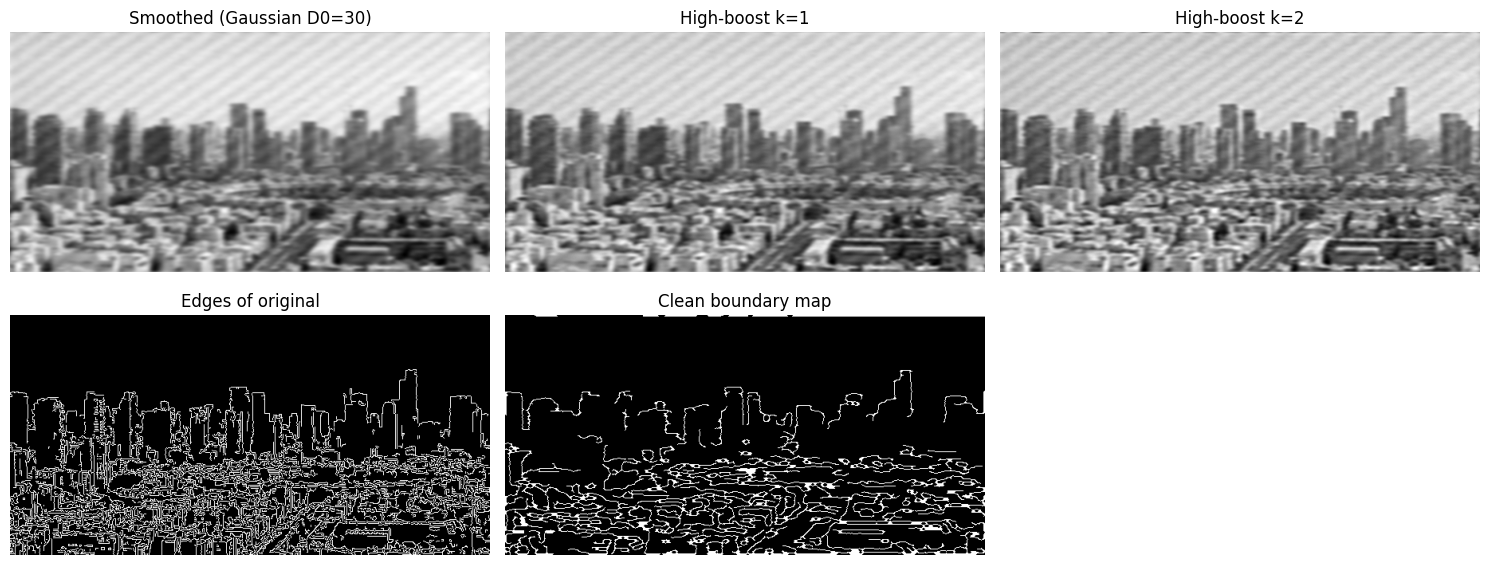

 

Image 4  (288x602)
Result                PSNR (dB)    SSIM   Sharpness
Original                    inf   1.000      2463.5
Ideal D0=30               26.12   0.424         8.4
Butterworth D0=30         26.34   0.438         7.7
Gaussian D0=30            26.49   0.449         9.2
Ideal D0=60               26.83   0.486        24.6
Butterworth D0=60         27.18   0.512        18.6
Gaussian D0=60            27.37   0.527        21.0
High-boost k=1            26.73   0.472        20.7
High-boost k=2            26.84   0.490        35.6
Edge pixels: original = 20.53%, after smoothing + sharpening + cleanup = 7.05%


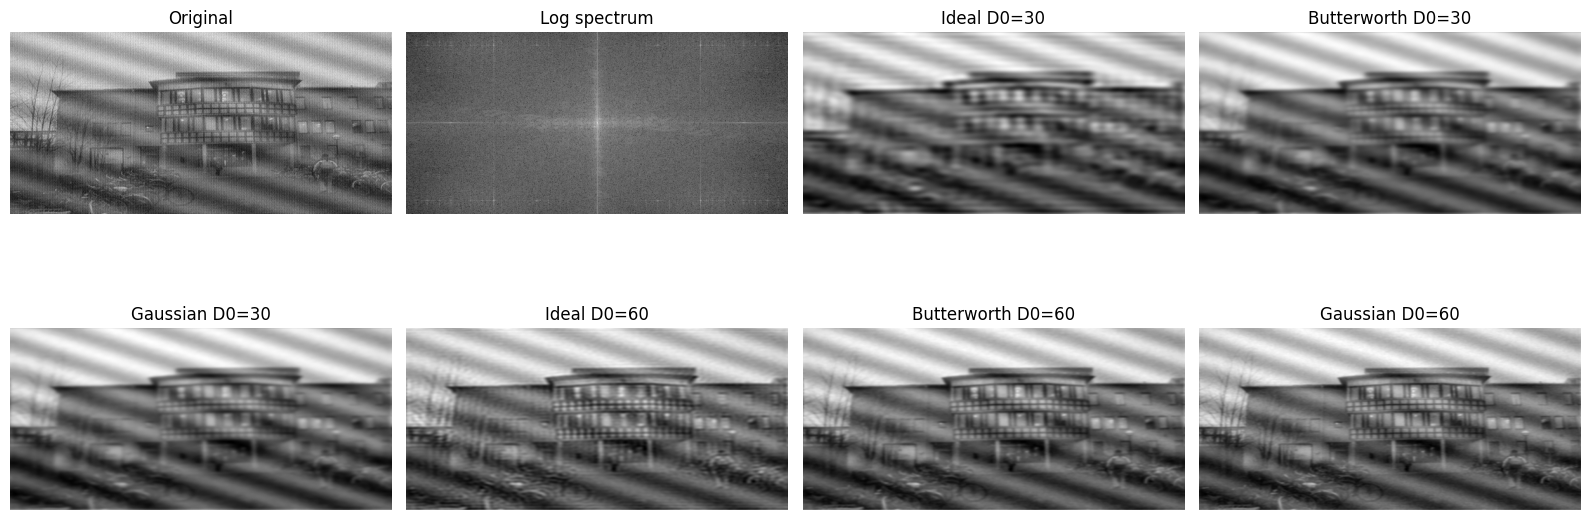

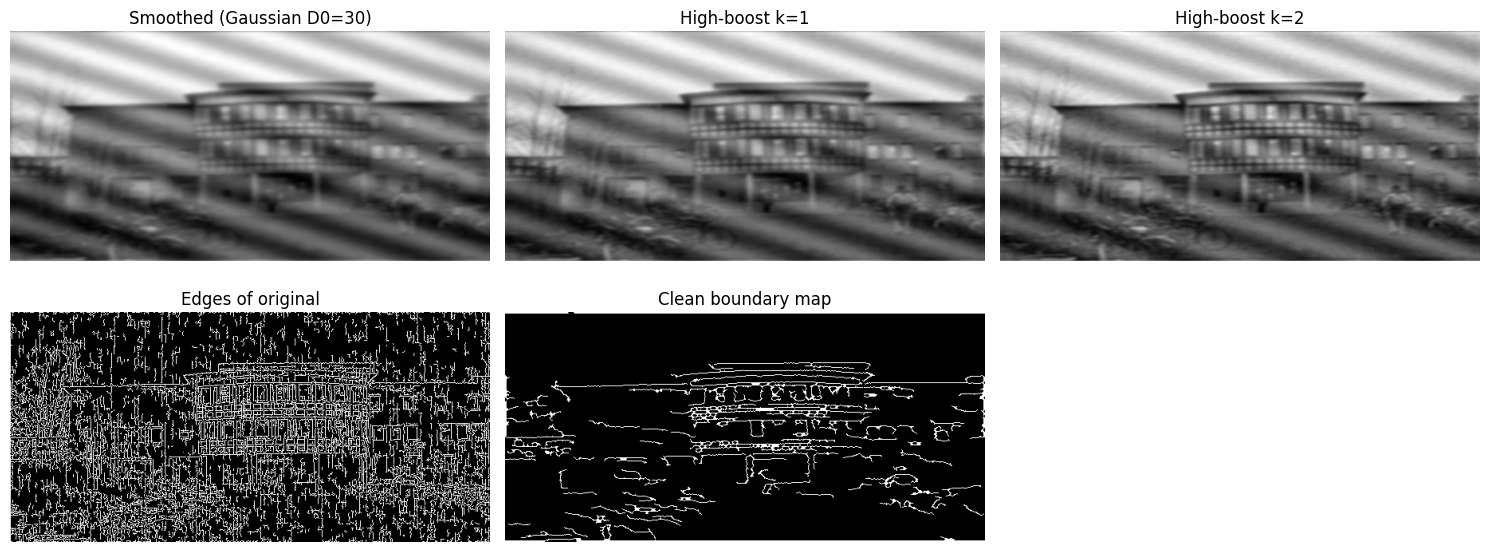

 

Image 5  (222x190)
Result                PSNR (dB)    SSIM   Sharpness
Original                    inf   1.000       276.0
Ideal D0=30               33.19   0.944        10.5
Butterworth D0=30         34.01   0.966         9.9
Gaussian D0=30            34.55   0.973        12.8
Ideal D0=60               36.18   0.981        54.8
Butterworth D0=60         37.76   0.991        44.3
Gaussian D0=60            39.18   0.993        60.8
High-boost k=1            35.54   0.980        29.9
High-boost k=2            35.98   0.981        50.5
Edge pixels: original = 7.46%, after smoothing + sharpening + cleanup = 6.60%


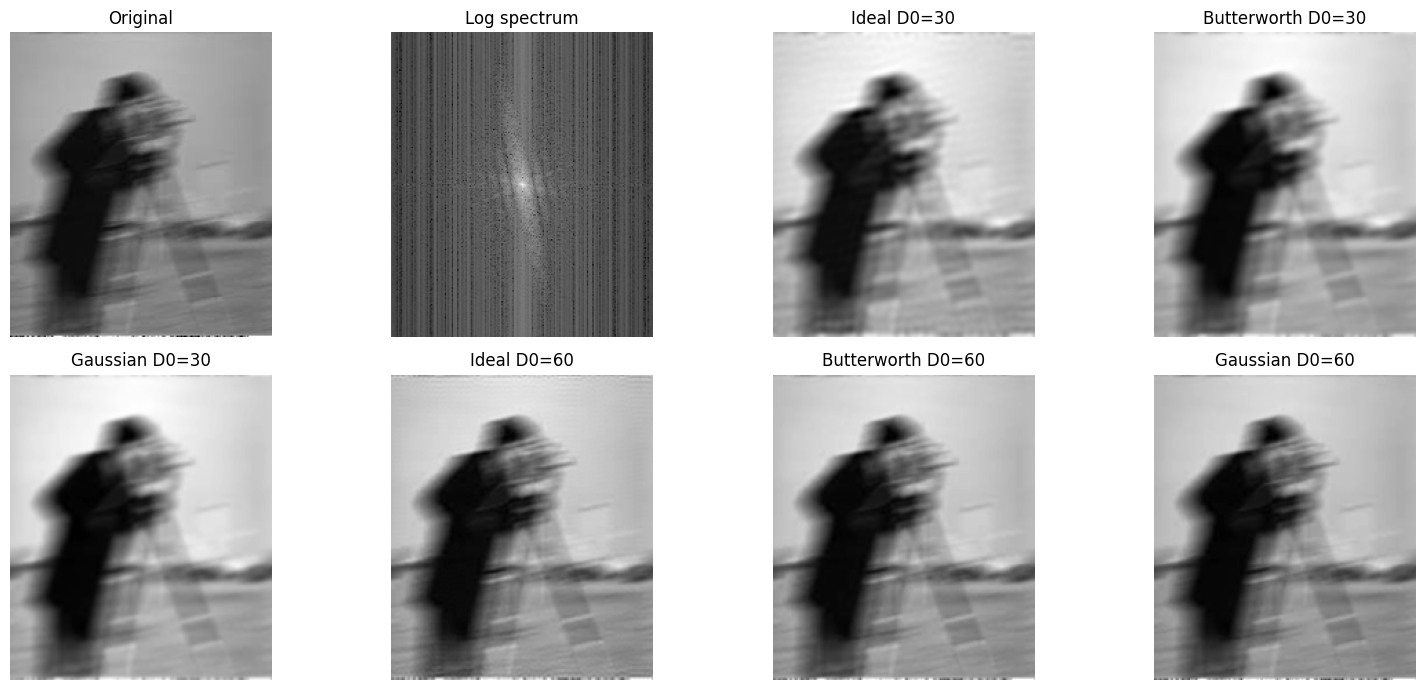

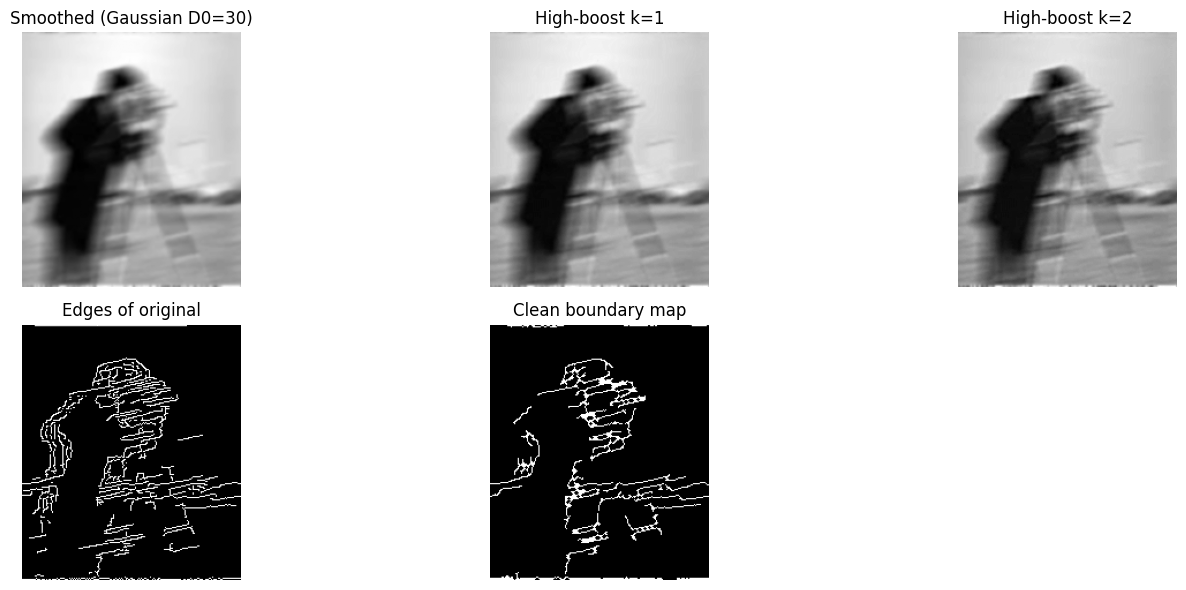

 
Done


In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity as ssim

for n in range(1, 6):

    # load in grayscale
    img = cv2.imread(f"image{n}.png", cv2.IMREAD_GRAYSCALE)
    M, N = img.shape

    # FFT, shift zero frequency to centre, log magnitude spectrum
    F = np.fft.fftshift(np.fft.fft2(img))
    spectrum = np.log(1 + np.abs(F))

    # distance of every frequency from the centre
    u = np.arange(M) - M / 2
    v = np.arange(N) - N / 2
    V, U = np.meshgrid(v, u)
    D = np.sqrt(U ** 2 + V ** 2)

    #low pass filters
    names = ["Original"]
    images = [img]

    for D0 in [30, 60]:
        H_ideal = (D <= D0).astype(float)
        H_butter = 1 / (1 + (D / D0) ** 4)            # order 2
        H_gauss = np.exp(-(D ** 2) / (2 * D0 ** 2))

        for fname, H in [("Ideal", H_ideal), ("Butterworth", H_butter), ("Gaussian", H_gauss)]:
            G = F * H
            out = np.real(np.fft.ifft2(np.fft.ifftshift(G)))
            out = np.uint8(np.clip(out, 0, 255))
            names.append(f"{fname} D0={D0}")
            images.append(out)
            if fname == "Gaussian" and D0 == 30:
                smooth = out          # this smoothed image is used for sharpening

    #high boost filter on the smoothed img
    F2 = np.fft.fftshift(np.fft.fft2(smooth))
    H_hp = 1 - np.exp(-(D ** 2) / (2 * 30 ** 2))      # Gaussian high-pass

    for k in [1, 2]:
        H_hb = 1 + k * H_hp                            # high-boost: keeps low freq, boosts high freq
        out = np.real(np.fft.ifft2(np.fft.ifftshift(F2 * H_hb)))
        out = np.uint8(np.clip(out, 0, 255))
        names.append(f"High-boost k={k}")
        images.append(out)

    sharp = images[-2]                                 # k=1 result used for boundary

    print(f"\nImage {n}  ({M}x{N})")
    print(f"{'Result':20s}{'PSNR (dB)':>11s}{'SSIM':>8s}{'Sharpness':>12s}")
    for name, im in zip(names, images):
        mse = np.mean((img.astype(float) - im.astype(float)) ** 2)
        psnr = 10 * np.log10(255 ** 2 / mse) if mse > 0 else float("inf")
        s = ssim(img, im, data_range=255)
        sharpness = cv2.Laplacian(im, cv2.CV_64F).var()
        print(f"{name:20s}{psnr:>11.2f}{s:>8.3f}{sharpness:>12.1f}")

    # BOUNDARY map
    # Canny with automatic thresholds taken from the gradient strength
    gx = cv2.Sobel(sharp, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(sharp, cv2.CV_64F, 0, 1, ksize=3)
    high = np.percentile(np.abs(gx) + np.abs(gy), 90)
    edges = cv2.Canny(sharp, 0.5 * high, high)

    # clean up: close small gaps, then remove tiny pieces
    se = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    edges = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, se)
    num, labels, stats, _ = cv2.connectedComponentsWithStats(edges, connectivity=8)
    keep = np.where(stats[:, cv2.CC_STAT_AREA] >= 30)[0]
    keep = keep[keep != 0]
    boundary = np.uint8(np.isin(labels, keep)) * 255

    # boundary of the original image for comparison
    gx0 = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
    gy0 = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)
    high0 = np.percentile(np.abs(gx0) + np.abs(gy0), 90)
    edges_orig = cv2.Canny(img, 0.5 * high0, high0)

    print(f"Edge pixels: original = {np.mean(edges_orig > 0) * 100:.2f}%, "
          f"after smoothing + sharpening + cleanup = {np.mean(boundary > 0) * 100:.2f}%")

    #spectrum and smoothing
    plt.figure(figsize=(16, 7))
    plt.subplot(2, 4, 1); plt.imshow(img, cmap="gray"); plt.title("Original"); plt.axis("off")
    plt.subplot(2, 4, 2); plt.imshow(spectrum, cmap="gray"); plt.title("Log spectrum"); plt.axis("off")
    for i in range(1, 7):
        plt.subplot(2, 4, i + 2)
        plt.imshow(images[i], cmap="gray")
        plt.title(names[i])
        plt.axis("off")
    plt.tight_layout()
    plt.savefig(f"image{n}_smoothing.png")
    plt.show()
    print(" ")

    #sharpening and boundary
    plt.figure(figsize=(15, 6))
    show = [smooth, images[-2], images[-1], edges_orig, boundary]
    titles = ["Smoothed (Gaussian D0=30)", "High-boost k=1", "High-boost k=2",
              "Edges of original", "Clean boundary map"]
    for i in range(5):
        plt.subplot(2, 3, i + 1)
        plt.imshow(show[i], cmap="gray")
        plt.title(titles[i])
        plt.axis("off")
    plt.tight_layout()
    plt.savefig(f"image{n}_sharpen_boundary.png")
    plt.show()
    print(" ")

    cv2.imwrite(f"image{n}_boundary.png", boundary)

print("Done")
